In [2]:
import pandas as pd
import mysql.connector
import matplotlib.pyplot as plt
import seaborn as sns
from getpass import getpass

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import mysql.connector
from getpass import getpass

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password=getpass("Enter MySQL password: "),
    database="flipkart"
)

print("MySQL connected successfully!")

Enter MySQL password:  ········


MySQL connected successfully!


In [4]:
query = """
SELECT *
FROM flipkart_ecommerce_analytics
"""

df = pd.read_sql(query, conn)

print("Data loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

C:\Users\singh\AppData\Local\Temp\ipykernel_14960\3843399985.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


Data loaded successfully!
Dataset shape: (20000, 22)


,Order_ID,Order_Date,Customer_ID,Customer_Name,Segment,City,State,Category,Sub_Category,Brand,...,Unit_Price,Discount_Pct,Discount_Amount,Sales,Cost,Profit,Payment_Mode,Order_Status,Month,Profit_Margin_Pct
0,ORD100000,2025-04-13,CUST10970,Customer_10970,Consumer,Mumbai,Maharashtra,Laptops,Gaming Laptops,Acer,...,53516.90,15,8027.54,0.00,38042.43,0.00,Debit Card,Returned,2025-04,0.00
1,ORD100001,2025-12-15,CUST11081,Customer_11081,Corporate,Jaipur,Rajasthan,Mobiles,Mobile Accessories,Realme,...,100.00,20,40.00,160.00,94.68,65.32,Credit Card,Delivered,2025-12,40.82
2,ORD100002,2025-09-28,CUST10598,Customer_10598,Corporate,Mumbai,Maharashtra,Laptops,Gaming Laptops,Asus,...,56707.67,5,2835.38,53872.29,34784.24,19088.05,UPI,Delivered,2025-09,35.43
3,ORD100003,2025-04-17,CUST10615,Customer_10615,Home Office,Mumbai,Maharashtra,Televisions,LED TV,TCL,...,39519.13,15,5927.87,33591.26,27087.82,6503.44,Debit Card,Delivered,2025-04,19.36
4,ORD100004,2025-03-13,CUST11167,Customer_11167,Consumer,Bangalore,Karnataka,Beauty,Skincare,Maybelline,...,1166.22,0,0.00,3498.66,2846.19,652.47,Debit Card,Delivered,2025-03,18.65


In [5]:
print("Rows:", df.shape[0])

Rows: 20000


In [6]:
print("Columns:", df.shape[1])

Columns: 22


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Order_ID           20000 non-null  str    
 1   Order_Date         20000 non-null  object 
 2   Customer_ID        20000 non-null  str    
 3   Customer_Name      20000 non-null  str    
 4   Segment            20000 non-null  str    
 5   City               20000 non-null  str    
 6   State              20000 non-null  str    
 7   Category           20000 non-null  str    
 8   Sub_Category       20000 non-null  str    
 9   Brand              20000 non-null  str    
 10  Product_Name       20000 non-null  str    
 11  Quantity           20000 non-null  int64  
 12  Unit_Price         20000 non-null  float64
 13  Discount_Pct       20000 non-null  int64  
 14  Discount_Amount    20000 non-null  float64
 15  Sales              20000 non-null  float64
 16  Cost               20000 non-null

In [8]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check duplicate Order_ID values
print("Duplicate Order IDs:", df["Order_ID"].duplicated().sum())


Duplicate rows: 10584
Duplicate Order IDs: 15000


In [9]:
# Display orders that appear multiple times
df["Order_ID"].value_counts().head(10)

Order_ID
ORD100000    4
ORD100001    4
ORD100002    4
ORD100003    4
ORD100004    4
ORD100005    4
ORD100006    4
ORD100007    4
ORD100008    4
ORD100009    4
Name: count, dtype: int64

In [10]:
df[df["Order_ID"] == "ORD100000"]

,Order_ID,Order_Date,Customer_ID,Customer_Name,Segment,City,State,Category,Sub_Category,Brand,...,Unit_Price,Discount_Pct,Discount_Amount,Sales,Cost,Profit,Payment_Mode,Order_Status,Month,Profit_Margin_Pct
0,ORD100000,2025-04-13,CUST10970,Customer_10970,Consumer,Mumbai,Maharashtra,Laptops,Gaming Laptops,Acer,...,53516.9,15,8027.54,0.0,38042.43,0.0,Debit Card,Returned,2025-04,0.0
5000,ORD100000,2025-04-13,CUST10970,Customer_10970,Consumer,Mumbai,Telangana,Laptops,Gaming Laptops,Acer,...,53516.9,15,8027.54,0.0,38042.43,0.0,Debit Card,Returned,2025-04,0.0
10000,ORD100000,2025-04-13,CUST10970,Customer_10970,Consumer,Mumbai,Telangana,Laptops,Gaming Laptops,Acer,...,53516.9,15,8027.54,0.0,38042.43,0.0,Debit Card,Returned,2025-04,0.0
15000,ORD100000,2025-04-13,CUST10970,Customer_10970,Consumer,Mumbai,Telangana,Laptops,Gaming Laptops,Acer,...,53516.9,15,8027.54,0.0,38042.43,0.0,Debit Card,Returned,2025-04,0.0


In [ ]:

# Check the number of unique values per column for ORD100000
order = df[df["Order_ID"] == "ORD100000"]

for col in df.columns:
    print(col, ":", order[col].nunique())     
    

Order_ID : 1
Order_Date : 1
Customer_ID : 1
Customer_Name : 1
Segment : 1
City : 1
State : 2
Category : 1
Sub_Category : 1
Brand : 1
Product_Name : 1
Quantity : 1
Unit_Price : 1
Discount_Pct : 1
Discount_Amount : 1
Sales : 1
Cost : 1
Profit : 1
Payment_Mode : 1
Order_Status : 1
Month : 1
Profit_Margin_Pct : 1


 # Check the duplicate pattern across the entire dataset

In [12]:

# Check whether each Order_ID has inconsistent values across columns
variation = df.groupby("Order_ID").nunique()

# Count orders where any column has multiple values
inconsistent_orders = variation.gt(1).any(axis=1).sum()

print("Total unique orders:", df["Order_ID"].nunique())
print("Orders with inconsistent details:", inconsistent_orders)

# Find which columns have inconsistencies
print("\nColumns with inconsistent values:")
print(variation.columns[variation.gt(1).any()].tolist())


Total unique orders: 5000
Orders with inconsistent details: 4416

Columns with inconsistent values:
['State']


 # Check all state values for one order

In [13]:

# Inspect state and location details for one order
df.loc[
    df["Order_ID"] == "ORD100000",
    ["Order_ID", "Customer_ID", "City", "State"]
]


,Order_ID,Customer_ID,City,State
0,ORD100000,CUST10970,Mumbai,Maharashtra
5000,ORD100000,CUST10970,Mumbai,Telangana
10000,ORD100000,CUST10970,Mumbai,Telangana
15000,ORD100000,CUST10970,Mumbai,Telangana


# Find all city–state combinations

In [14]:

# Check which states are associated with each city
city_state = df[["City", "State"]].drop_duplicates()

print("Total unique city-state combinations:", len(city_state))
display(city_state.sort_values("City").head(30))


Total unique city-state combinations: 90


,City,State
4,Bangalore,Karnataka
5004,Bangalore,Rajasthan
5034,Bangalore,Maharashtra
5043,Bangalore,Delhi
5091,Bangalore,Tamil Nadu
5153,Bangalore,West Bengal
5162,Bangalore,Uttar Pradesh
5176,Bangalore,Haryana
5448,Bangalore,Telangana
18,Chennai,Tamil Nadu


# Check whether the original 5,000 rows are intact

In [15]:

# Compare the first two 5,000-row blocks
block1 = df.iloc[0:5000].reset_index(drop=True)
block2 = df.iloc[5000:10000].reset_index(drop=True)

print("Rows in block 1:", len(block1))
print("Rows in block 2:", len(block2))

print(
    "Identical except for State:",
    block1.drop(columns=["State"]).equals(
        block2.drop(columns=["State"])
    )
)

print(
    "State values identical:",
    block1["State"].equals(block2["State"])
)


Rows in block 1: 5000
Rows in block 2: 5000
Identical except for State: True
State values identical: False


# Compare all four blocks

In [16]:

# Compare all four 5,000-row blocks
block1 = df.iloc[0:5000].reset_index(drop=True)

for start in [5000, 10000, 15000]:
    block = df.iloc[start:start + 5000].reset_index(drop=True)

    print(f"\nComparing rows {start} to {start + 4999}")
    print(
        "Identical except for State:",
        block1.drop(columns=["State"]).equals(
            block.drop(columns=["State"])
        )
    )
    print(
        "State values identical:",
        block1["State"].equals(block["State"])
    )



Comparing rows 5000 to 9999
Identical except for State: True
State values identical: False

Comparing rows 10000 to 14999
Identical except for State: True
State values identical: False

Comparing rows 15000 to 19999
Identical except for State: True
State values identical: False


# Create a clean working copy

In [17]:

# Preserve the complete dataset
df_original = df.copy()

# Create a provisional working dataset from the first block
df_clean = df.iloc[:5000].copy().reset_index(drop=True)

print("Original rows:", len(df_original))
print("Working rows:", len(df_clean))
print("Unique order IDs:", df_clean["Order_ID"].nunique())
print("Duplicate full rows:", df_clean.duplicated().sum())


Original rows: 20000
Working rows: 5000
Unique order IDs: 5000
Duplicate full rows: 0


# Convert Order_Date to datetime

In [18]:

# Convert Order_Date to datetime
df_clean["Order_Date"] = pd.to_datetime(
    df_clean["Order_Date"],
    errors="coerce"
)

# Verify the conversion
print("Order_Date data type:", df_clean["Order_Date"].dtype)
print("Invalid dates:", df_clean["Order_Date"].isna().sum())

# Display sample dates
display(df_clean[["Order_ID", "Order_Date"]].head())


Order_Date data type: datetime64[s]
Invalid dates: 0


,Order_ID,Order_Date
0,ORD100000,2025-04-13
1,ORD100001,2025-12-15
2,ORD100002,2025-09-28
3,ORD100003,2025-04-17
4,ORD100004,2025-03-13


# Check missing values

In [19]:

# Count missing values in each column
missing_values = df_clean.isnull().sum()

print("Missing values in each column:")
display(missing_values)

print("\nTotal missing values:", missing_values.sum())


Missing values in each column:


Order_ID             0
Order_Date           0
Customer_ID          0
Customer_Name        0
Segment              0
City                 0
State                0
Category             0
Sub_Category         0
Brand                0
Product_Name         0
Quantity             0
Unit_Price           0
Discount_Pct         0
Discount_Amount      0
Sales                0
Cost                 0
Profit               0
Payment_Mode         0
Order_Status         0
Month                0
Profit_Margin_Pct    0
dtype: int64


Total missing values: 0


# Check numeric values and business logic

In [20]:

# Summary statistics for numeric columns
display(df_clean.describe().round(2))


,Order_Date,Quantity,Unit_Price,Discount_Pct,Discount_Amount,Sales,Cost,Profit,Profit_Margin_Pct
count,5000,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,2025-07-01 12:02:35,1.57,17161.77,11.65,3153.80,16215.75,17064.78,4613.18,18.93
min,2025-01-01 00:00:00,1.00,100.00,0.00,0.00,0.00,53.82,0.00,0.00
25%,2025-04-03 00:00:00,1.00,1251.07,5.00,107.10,0.00,1171.08,0.00,0.00
50%,2025-06-28 00:00:00,1.00,7946.06,10.00,591.44,1643.02,6527.16,454.74,21.38
75%,2025-10-01 00:00:00,2.00,28564.90,15.00,3887.24,22513.90,25003.67,5670.49,31.89
max,2025-12-31 00:00:00,3.00,112102.54,30.00,100892.29,290113.08,201079.33,103748.61,42.00
std,NaN,0.72,19885.93,8.03,5713.52,29660.38,23744.92,8856.99,14.79


# Check sales, cost, and profit together

In [21]:

# Check zero sales
print("Zero-sales rows:", (df_clean["Sales"] == 0).sum())

# Check zero cost
print("Zero-cost rows:", (df_clean["Cost"] == 0).sum())

# Check negative profit
print("Negative-profit rows:", (df_clean["Profit"] < 0).sum())

# Inspect records with zero sales
display(
    df_clean.loc[
        df_clean["Sales"] == 0,
        ["Order_ID", "Order_Status", "Quantity",
         "Sales", "Cost", "Profit"]
    ].head(10)
)


Zero-sales rows: 1639
Zero-cost rows: 0
Negative-profit rows: 0


,Order_ID,Order_Status,Quantity,Sales,Cost,Profit
0,ORD100000,Returned,1,0.0,38042.43,0.0
7,ORD100007,Cancelled,1,0.0,5188.26,0.0
8,ORD100008,Returned,3,0.0,50177.54,0.0
12,ORD100012,Returned,1,0.0,18540.20,0.0
16,ORD100016,Cancelled,1,0.0,4688.43,0.0
21,ORD100021,Returned,1,0.0,705.30,0.0
23,ORD100023,Returned,1,0.0,2095.41,0.0
24,ORD100024,Cancelled,1,0.0,10705.15,0.0
25,ORD100025,Returned,2,0.0,36805.26,0.0
29,ORD100029,Cancelled,2,0.0,34890.19,0.0


# Check the number of orders by status

In [22]:

# Count orders by status
print(df_clean["Order_Status"].value_counts())

# Compare sales, cost, and profit by status
status_summary = df_clean.groupby("Order_Status").agg(
    Order_Count=("Order_ID", "count"),
    Total_Sales=("Sales", "sum"),
    Total_Cost=("Cost", "sum"),
    Total_Profit=("Profit", "sum")
).round(2)

display(status_summary)


Order_Status
Delivered    3361
Cancelled     826
Returned      813
Name: count, dtype: int64


,Order_Count,Total_Sales,Total_Cost,Total_Profit
Order_Status,,,,
Cancelled,826,0.00,13903781.94,0.00
Delivered,3361,81078729.08,58012852.32,23065876.76
Returned,813,0.00,13407255.86,0.00


# Verify the profit formula

In [23]:

# Check profit calculation for delivered orders
delivered = df_clean[
    df_clean["Order_Status"] == "Delivered"
].copy()

delivered["Calculated_Profit"] = (
    delivered["Sales"] - delivered["Cost"]
)

delivered["Profit_Difference"] = (
    delivered["Profit"] - delivered["Calculated_Profit"]
).round(2)

print(
    "Rows where profit does not equal Sales - Cost:",
    (delivered["Profit_Difference"].abs() > 0.01).sum()
)

display(
    delivered[
        ["Order_ID", "Sales", "Cost", "Profit",
         "Calculated_Profit", "Profit_Difference"]
    ].head(10)
)


Rows where profit does not equal Sales - Cost: 0


,Order_ID,Sales,Cost,Profit,Calculated_Profit,Profit_Difference
1,ORD100001,160.00,94.68,65.32,65.32,0.0
2,ORD100002,53872.29,34784.24,19088.05,19088.05,-0.0
3,ORD100003,33591.26,27087.82,6503.44,6503.44,-0.0
4,ORD100004,3498.66,2846.19,652.47,652.47,0.0
5,ORD100005,43755.39,26744.84,17010.55,17010.55,0.0
6,ORD100006,166080.80,141609.42,24471.38,24471.38,0.0
9,ORD100009,61935.21,43830.97,18104.24,18104.24,0.0
10,ORD100010,550.56,365.13,185.43,185.43,0.0
11,ORD100011,17562.74,10924.13,6638.61,6638.61,-0.0
13,ORD100013,1279.26,949.76,329.50,329.50,0.0


# Validate profit margins

In [24]:

# Check profit margin for delivered orders
delivered["Calculated_Margin_Pct"] = (
    delivered["Profit"] / delivered["Sales"] * 100
)

delivered["Margin_Difference"] = (
    delivered["Profit_Margin_Pct"]
    - delivered["Calculated_Margin_Pct"]
).abs()

print(
    "Rows with margin mismatch:",
    (delivered["Margin_Difference"] > 0.1).sum()
)

display(
    delivered[
        ["Order_ID", "Sales", "Profit",
         "Profit_Margin_Pct", "Calculated_Margin_Pct"]
    ].head(10).round(2)
)


Rows with margin mismatch: 0


,Order_ID,Sales,Profit,Profit_Margin_Pct,Calculated_Margin_Pct
1,ORD100001,160.00,65.32,40.82,40.82
2,ORD100002,53872.29,19088.05,35.43,35.43
3,ORD100003,33591.26,6503.44,19.36,19.36
4,ORD100004,3498.66,652.47,18.65,18.65
5,ORD100005,43755.39,17010.55,38.88,38.88
6,ORD100006,166080.80,24471.38,14.73,14.73
9,ORD100009,61935.21,18104.24,29.23,29.23
10,ORD100010,550.56,185.43,33.68,33.68
11,ORD100011,17562.74,6638.61,37.80,37.80
13,ORD100013,1279.26,329.50,25.76,25.76


# Calculate core KPIs using delivered orders

In [25]:

# Calculate core KPIs using delivered orders
delivered = df_clean[
    df_clean["Order_Status"] == "Delivered"
]

total_orders = df_clean["Order_ID"].nunique()
delivered_orders = len(delivered)
cancelled_orders = (df_clean["Order_Status"] == "Cancelled").sum()
returned_orders = (df_clean["Order_Status"] == "Returned").sum()

total_sales = delivered["Sales"].sum()
total_profit = delivered["Profit"].sum()
profit_margin = total_profit / total_sales * 100
avg_order_value = total_sales / delivered_orders

print("Total Orders:", total_orders)
print("Delivered Orders:", delivered_orders)
print("Cancelled Orders:", cancelled_orders)
print("Returned Orders:", returned_orders)
print("Delivered Sales: ₹", round(total_sales, 2))
print("Delivered Profit: ₹", round(total_profit, 2))
print("Profit Margin (%):", round(profit_margin, 2))
print("Average Order Value: ₹", round(avg_order_value, 2))


Total Orders: 5000
Delivered Orders: 3361
Cancelled Orders: 826
Returned Orders: 813
Delivered Sales: ₹ 81078729.08
Delivered Profit: ₹ 23065876.76
Profit Margin (%): 28.45
Average Order Value: ₹ 24123.39


# Monthly sales and profit for delivered orders

In [27]:

# Monthly sales and profit for delivered orders
monthly_summary = (
    df_clean[df_clean["Order_Status"] == "Delivered"]
    .groupby(df_clean["Order_Date"].dt.to_period("M"))
    .agg(
        Orders=("Order_ID", "nunique"),
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
    .reset_index()
)

monthly_summary["Order_Date"] = (
    monthly_summary["Order_Date"].astype(str)
)

monthly_summary = monthly_summary.round(2)

display(monthly_summary)


,Order_Date,Orders,Sales,Profit
0,2025-01,278,6469290.15,1700328.90
1,2025-02,253,6115920.55,1735366.73
2,2025-03,282,6652362.13,1973867.71
3,2025-04,303,7729242.02,2101362.03
4,2025-05,300,6920188.71,1907883.52
5,2025-06,291,7823984.93,2295307.44
6,2025-07,267,6852632.06,2049192.87
7,2025-08,284,6355343.08,1845161.40
8,2025-09,258,5434078.42,1538068.83
9,2025-10,282,6652314.88,1921126.04


 # create a bar chart comparing monthly sales.

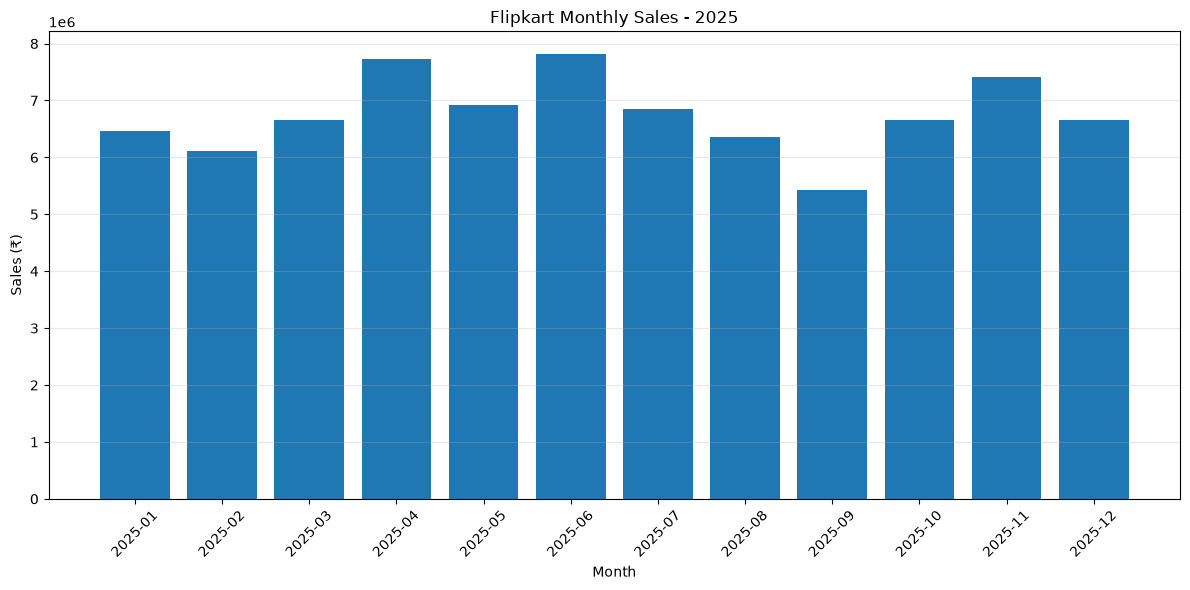

In [28]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    monthly_summary["Order_Date"],
    monthly_summary["Sales"]
)

plt.title("Flipkart Monthly Sales - 2025")
plt.xlabel("Month")
plt.ylabel("Sales (₹)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Create a monthly profit chart

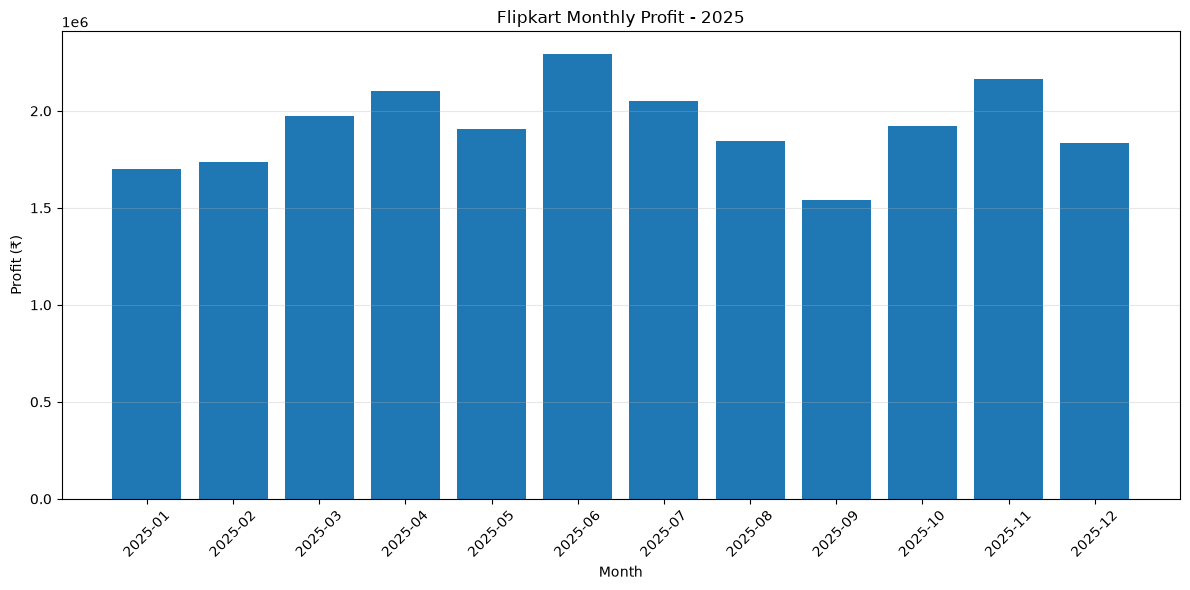

In [29]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    monthly_summary["Order_Date"],
    monthly_summary["Profit"]
)

plt.title("Flipkart Monthly Profit - 2025")
plt.xlabel("Month")
plt.ylabel("Profit (₹)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Create a professional sales vs. profit chart

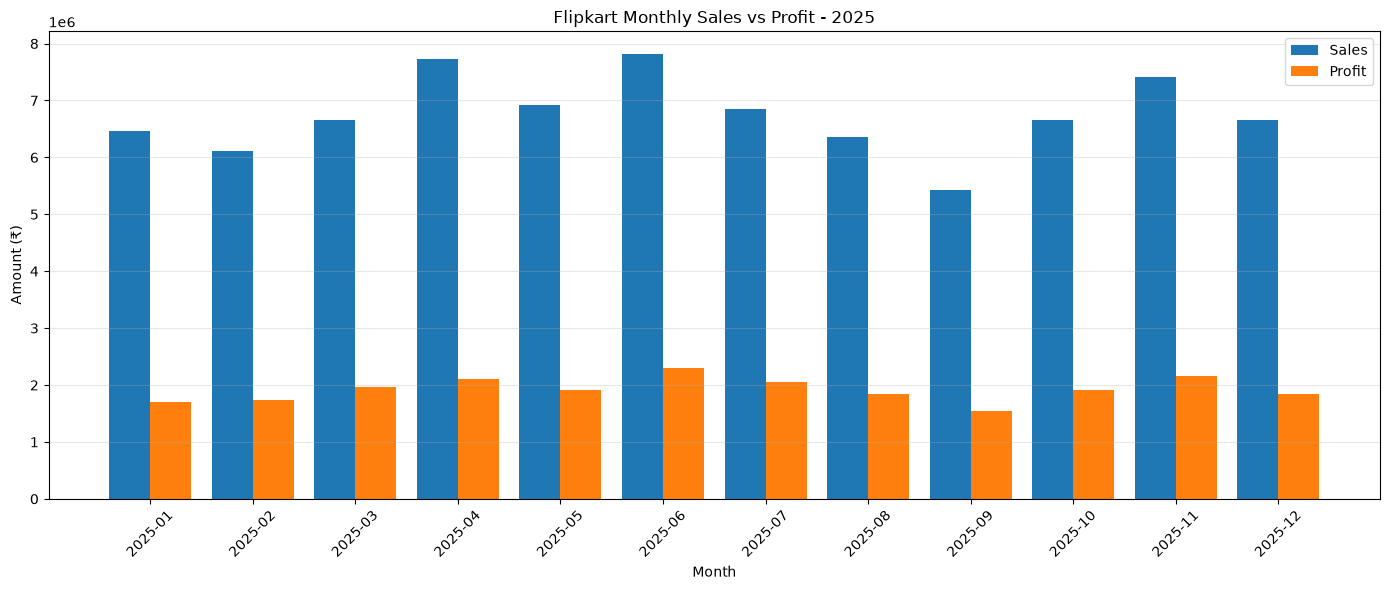

In [30]:

import matplotlib.pyplot as plt
import numpy as np

months = monthly_summary["Order_Date"]
x = np.arange(len(months))
width = 0.4

plt.figure(figsize=(14, 6))

plt.bar(
    x - width / 2,
    monthly_summary["Sales"],
    width,
    label="Sales"
)

plt.bar(
    x + width / 2,
    monthly_summary["Profit"],
    width,
    label="Profit"
)

plt.title("Flipkart Monthly Sales vs Profit - 2025")
plt.xlabel("Month")
plt.ylabel("Amount (₹)")
plt.xticks(x, months, rotation=45)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Calculate monthly profit margin

In [31]:

monthly_summary["Profit_Margin_Pct"] = (
    monthly_summary["Profit"] /
    monthly_summary["Sales"] * 100
).round(2)

display(
    monthly_summary[
        ["Order_Date", "Sales", "Profit", "Profit_Margin_Pct"]
    ]
)


,Order_Date,Sales,Profit,Profit_Margin_Pct
0,2025-01,6469290.15,1700328.90,26.28
1,2025-02,6115920.55,1735366.73,28.37
2,2025-03,6652362.13,1973867.71,29.67
3,2025-04,7729242.02,2101362.03,27.19
4,2025-05,6920188.71,1907883.52,27.57
5,2025-06,7823984.93,2295307.44,29.34
6,2025-07,6852632.06,2049192.87,29.90
7,2025-08,6355343.08,1845161.40,29.03
8,2025-09,5434078.42,1538068.83,28.30
9,2025-10,6652314.88,1921126.04,28.88


# Create a profit margin chart

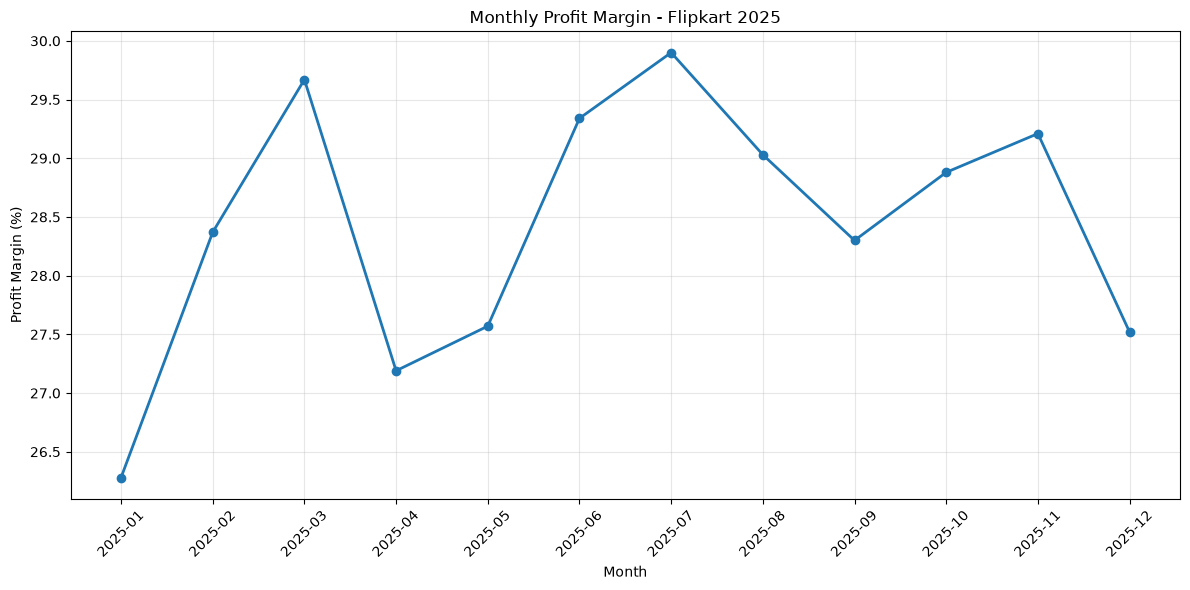

In [32]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_summary["Order_Date"],
    monthly_summary["Profit_Margin_Pct"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Profit Margin - Flipkart 2025")
plt.xlabel("Month")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Export the cleaned working dataset to CSV

In [33]:

# Export the cleaned working dataset to CSV
df_clean.to_csv(
    "flipkart_cleaned.csv",
    index=False
)

print("CSV file exported successfully!")
print("Rows:", len(df_clean))
print("Columns:", len(df_clean.columns))


CSV file exported successfully!
Rows: 5000
Columns: 22


In [34]:

import os

print(os.getcwd())


C:\Users\singh


In [35]:

import os

print("Your notebook folder is:")
print(os.getcwd())

print("\nCSV file exists:", os.path.exists("flipkart_cleaned.csv"))


Your notebook folder is:
C:\Users\singh

CSV file exists: True
